In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3

from scipy.ndimage import map_coordinates

In [2]:
Nbins = 400

kappa_masterlist = np.loadtxt('microlensing_mpd/kappa_list.txt')
gamma_masterlist = np.loadtxt('microlensing_mpd/gamma_list.txt')
s_masterlist     = np.loadtxt('microlensing_mpd/s_list.txt')
log10_mu         = np.loadtxt('microlensing_mpd/log10_mu.txt')

data = np.load('/media/data/imf_with_doubles/test/mpd_grid.npy')

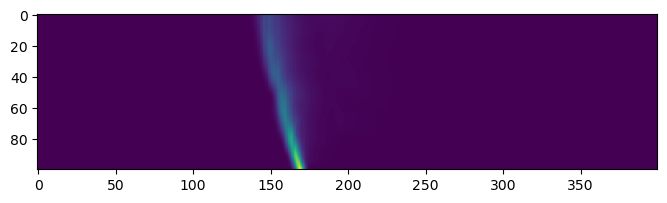

In [3]:
fig, ax = plt.subplots(1, 1, figsize=(8,8))

ax.imshow(data[:, 22, 22, :].T)

In [4]:
Nbins = 400

kappa_new = 0.4
gamma_new = 0.4
s_new     = 66

log10_mu_new_index = np.arange(Nbins)

kappa_new_index = (kappa_new - kappa_masterlist[0]) / 0.01 * np.ones_like(log10_mu_new_index)
gamma_new_index = (gamma_new - gamma_masterlist[0]) / 0.01 * np.ones_like(log10_mu_new_index)
s_new_index     = (s_new - s_masterlist[0])                * np.ones_like(log10_mu_new_index)

print(kappa_new_index[0], gamma_new_index[0], s_new_index[0])

coords = np.asarray([log10_mu_new_index, kappa_new_index, gamma_new_index, s_new_index])

35.0 40.0 66.0


In [5]:
p_mu_new = map_coordinates(data, coords, order=0)

In [6]:
## load Luke's mpds
kappa = 0.4
gamma = 0.4
s = 0.5

mu_macro = 1 / ((1 - kappa)**2 - gamma**2)

filename = 'k_' + str(kappa) + '_y_' + str(gamma) + '_s_' + str(s) + '.npy'

#log_mu, p_log_mu = np.load('/home/favio/software/notebooks/imf_with_doubles/bayesian_microlensing/data/histograms/k_0.38_y_0.38_s_0.96.npy').T
log_mu, p_log_mu = np.load('/home/favio/software/notebooks/imf_with_doubles/bayesian_microlensing/data/histograms/' + filename).T
## normalize p
p_log_mu = p_log_mu / np.sum(p_log_mu)
## normalize to mu_macro
log_mu = log_mu  - np.log10(mu_macro)

In [7]:
np.sum(p_log_mu)

0.9999999999999999

In [8]:
np.sum(p_mu_new)

0.9988332952595609

/tmp/ipykernel_6880/3255408940.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


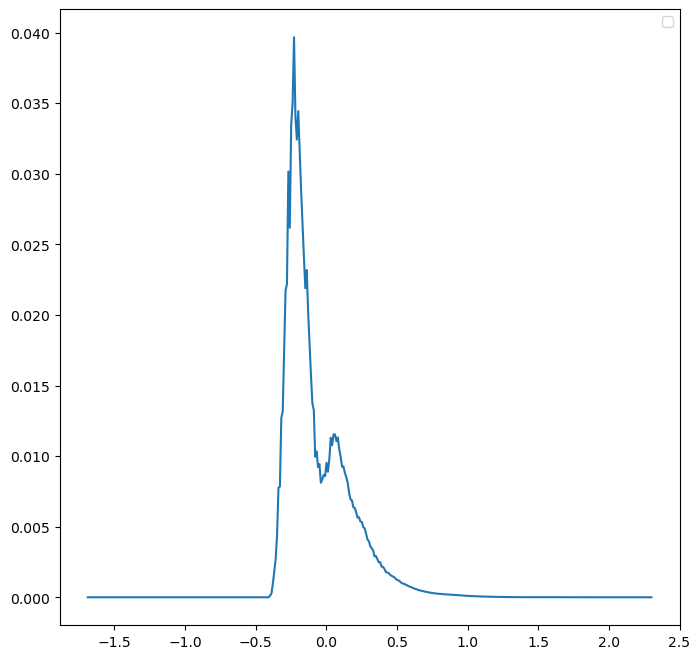

In [10]:
fig, ax = plt.subplots(1, 1, figsize=(8,8))

#ax.plot(log_mu, p_log_mu, label='Luke')

ax.plot(log10_mu, p_mu_new)

ax.legend()